In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import math
import torch.nn.functional as F
from torch.utils.data import Subset
import numpy as np
import pandas as pd
import copy
from torch.utils.data import ConcatDataset
from IPython.display import clear_output

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import math
import torch.nn.functional as F
from torch.utils.data import Subset
import numpy as np
import pandas as pd
import copy
from torch.utils.data import ConcatDataset
from torchvision.datasets import ImageFolder
from torchvision import transforms
from torch.utils.data import DataLoader
import os
from IPython.display import clear_output
from tqdm.notebook import tqdm

In [3]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from tqdm.notebook import tqdm

# 1. Setup Data
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
train_set = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_set = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

loader = DataLoader(train_set, batch_size=128, shuffle=True)
test_loader = DataLoader(test_set, batch_size=128, shuffle=False)

# 2. Basic Encoder + Temporary Classifier Head
encoder = nn.Sequential(
    nn.Conv2d(1, 16, 3, stride=2, padding=1), nn.ReLU(),
    nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.ReLU(),
    nn.Flatten(),
    nn.Linear(32 * 7 * 7, 64) 
).to("cuda")

# A 10-class head just to track accuracy during training
classifier_head = nn.Linear(64, 10).to("cuda")

# 3. Training Setup
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(list(encoder.parameters()) + list(classifier_head.parameters()), lr=1e-3)


In [4]:
# Assuming alpha_bar is already defined as:
beta = torch.linspace(1e-4, 0.02, 500).to("cuda")
alpha = 1. - beta
alpha_bar = torch.cumprod(alpha, dim=0)

for epoch in tqdm(range(2), desc="Total Epochs"):
    # --- Training Phase ---
    encoder.train()
    classifier_head.train()
    pbar = tqdm(loader, desc=f"Epoch {epoch} Training", leave=False)
    
    for imgs, labels in pbar:
        imgs, labels = imgs.to("cuda"), labels.to("cuda")
        B = imgs.shape[0]
        
        # --- RANDOMLY NOISE THE INPUTS ---
        # Pick random timesteps for each image in the batch
        t = torch.randint(0, 500, (B,), device="cuda").long()
        noise = torch.randn_like(imgs)
        
        # Grab the corresponding alpha_bar values
        a_bar = alpha_bar[t].view(-1, 1, 1, 1)
        
        # Forward diffusion process: x_t = sqrt(alpha_bar)*x_0 + sqrt(1-alpha_bar)*epsilon
        noised_imgs = torch.sqrt(a_bar) * imgs + torch.sqrt(1 - a_bar) * noise
        
        # --- TRAIN ON NOISED DATA ---
        features = encoder(noised_imgs)
        logits = classifier_head(features)
        loss = criterion(logits, labels)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        pbar.set_postfix(loss=f"{loss.item():.4f}")

    # --- Testing Phase ---
    encoder.eval()
    classifier_head.eval()
    correct, total = 0, 0
    
    with torch.no_grad():
        for imgs, labels in tqdm(test_loader, desc="Testing", leave=False):
            imgs, labels = imgs.to("cuda"), labels.to("cuda")
            
            # Note: We test on clean images to check fundamental accuracy,
            # but you could also noise these to check "Noised Accuracy".
            features = encoder(imgs)
            logits = classifier_head(features)
            
            _, predicted = torch.max(logits.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    print(f"Epoch {epoch} | Clean Test Accuracy: {accuracy:.2f}%")

Total Epochs:   0%|          | 0/2 [00:00<?, ?it/s]

Epoch 0 Training:   0%|          | 0/469 [00:00<?, ?it/s]

Testing:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch 0 | Clean Test Accuracy: 94.04%


Epoch 1 Training:   0%|          | 0/469 [00:00<?, ?it/s]

Testing:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch 1 | Clean Test Accuracy: 95.95%


In [6]:
# 1. Prepare Data: Numerator (8s) and Denominator (All)
all_imgs = next(iter(DataLoader(train_set, batch_size=2000, shuffle=True)))[0].to("cuda")
is_eight = (train_set.targets == 8).nonzero(as_tuple=True)[0]
eight_imgs = train_set.data[is_eight[:1000]].unsqueeze(1).float().to("cuda") / 255.0

# 2. Extract Latent Features (X)
with torch.no_grad():
    phi_all = encoder(all_imgs)    # Features of the background distribution (De)
    phi_eight = encoder(eight_imgs) # Features of the target distribution (Nu)

# 3. Analytical Solution: theta = H^-1 * h
# H = (1/n_de) * sum(phi_all * phi_all^T) + lambda * I
# h = (1/n_nu) * sum(phi_eight)

n_de = phi_all.shape[0]
n_nu = phi_eight.shape[0]
reg = 0.1 # Regularization parameter lambda

# Calculate H (64x64 matrix)
H = (phi_all.T @ phi_all) / n_de
H += reg * torch.eye(64).to("cuda")

# Calculate h (64x1 vector)
h = torch.mean(phi_eight, dim=0, keepdim=True).T

# Solve for theta (The "1-Shot" moment)
theta = torch.linalg.solve(H, h)

print("Analytical weights theta calculated!")

Analytical weights theta calculated!


In [7]:
class BinaryClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=3, padding=1),
            nn.GroupNorm(32, 64), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.GroupNorm(32, 128), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.GroupNorm(32, 256), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.GroupNorm(32, 512), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten()
        )
        
        self.time_mlp = nn.Sequential(
            nn.Linear(1, 128),
            nn.ReLU(),
            nn.Linear(128, 128)
        )
        
        self.fc = nn.Linear(512 + 128, 2)

    def forward(self, x, t):
        img_feats = self.features(x)
        
        if t.dim() == 1:
            t = t.unsqueeze(-1).float()
            
        time_feats = self.time_mlp(t)
        
        combined = torch.cat([img_feats, time_feats], dim=1)
        return self.fc(combined)


class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels, groups=8):
        super().__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(groups, out_channels),  # GroupNorm is standard for Diffusion
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(groups, out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.double_conv(x)

class uNet(nn.Module):
    def __init__(self, time_dim=128):
        super().__init__()
        self.time_mlp = nn.Sequential(
            nn.Linear(1, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )

        self.input = DoubleConv(1, 64)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(128, 256))

        self.bottleneck = DoubleConv(256, 512)

        self.up1 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.conv_up1 = DoubleConv(384, 256)
        
        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.conv_up2 = DoubleConv(192, 128)

        self.output = nn.Conv2d(128, 1, kernel_size=1)

        self.emb_down1 = nn.Linear(time_dim, 128)
        self.emb_down2 = nn.Linear(time_dim, 256)
        self.emb_up1 = nn.Linear(time_dim, 256)
        self.emb_up2 = nn.Linear(time_dim, 128)

    def forward(self, x, t):
        t = t.view(-1, 1) 
        emb = self.time_mlp(t)
        
        x1 = self.input(x)
        
        x2 = self.down1(x1)
        x2 = x2 + self.emb_down1(emb)[:, :, None, None]
        
        x3 = self.down2(x2)
        x3 = x3 + self.emb_down2(emb)[:, :, None, None]

        x_mid = self.bottleneck(x3)

        x_up1 = self.up1(x_mid)
        x_up1 = torch.cat([x_up1, x2], dim=1)
        x_up1 = self.conv_up1(x_up1) 
        x_up1 = x_up1 + self.emb_up1(emb)[:, :, None, None]
        
        x_up2 = self.up2(x_up1)
        x_up2 = torch.cat([x_up2, x1], dim=1)
        x_up2 = self.conv_up2(x_up2)
        x_up2 = x_up2 + self.emb_up2(emb)[:, :, None, None]

        return self.output(x_up2)

class Classifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 64, 3, padding=1),
            nn.GroupNorm(16, 64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.1),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.GroupNorm(16, 128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.2),

            nn.Conv2d(128, 256, 3, padding=1),
            nn.GroupNorm(16, 256),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.3),

            nn.AdaptiveAvgPool2d(1),
            nn.Flatten()
        )

        self.fc = nn.Linear(256, 10)

    def forward(self, x):
        x = self.features(x)
        return self.fc(x)

In [8]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
biCls = BinaryClassifier().to(device)
cls = Classifier().to(device)
model = uNet().to(device)

biCls.load_state_dict(torch.load("8_binary_clsf.pth", map_location=device))
cls.load_state_dict(torch.load("mnist_cnn_wei.pth", map_location=device))
model.load_state_dict(torch.load("uncond_diff_wei.pth", map_location=device))

<All keys matched successfully>

In [9]:
img_size = 28
batch_size = 128
epochs = 100
timesteps = 500
img_size = 28

beta = torch.linspace(1e-4, 0.02, timesteps).to(device)
alpha = 1. - beta
alpha_bar = torch.cumprod(alpha, dim=0)

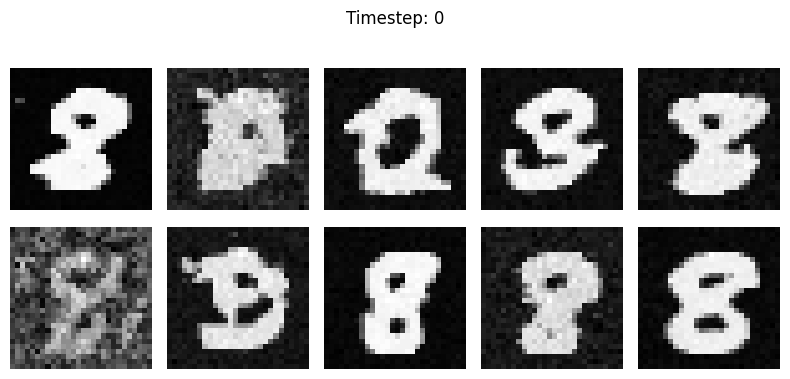

In [11]:
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

# ... (Previous code: model, encoder, theta, alpha, beta setup) ...

n_samples = 50
s = 100.0  # Set scale > 0 to see the guidance effect
img_size = 28
device = "cuda"

# Start with random noise
xt = torch.randn(n_samples, 1, img_size, img_size).to(device)

for i in reversed(range(timesteps)):
    t = torch.tensor([i] * n_samples, device=device)
    t_float = t.float() / timesteps
    
    # 1. Unconditional prediction (no grad needed)
    with torch.no_grad():
        eps_pred = model(xt, t_float)
    
    alpha_t = alpha[i]
    alpha_bar_t = alpha_bar[i]
    beta_t = beta[i]

    # Standard Diffusion Mean
    mean = (xt - ((1 - alpha_t) / torch.sqrt(1 - alpha_bar_t)) * eps_pred) / torch.sqrt(alpha_t)

    # 2. uLSIF Guidance (Requires Grad)
    # Use a clone that tracks gradients
    xt_for_grad = xt.detach().requires_grad_(True)
    
    features = encoder(xt_for_grad)
    ratio = features @ theta
    log_r = torch.log(torch.clamp(ratio, min=1e-8))
    
    # Calculate gradient of log-ratio w.r.t xt
    guide_score = torch.autograd.grad(log_r.sum(), xt_for_grad)[0]
    
    # Update mean with guidance
    mean = mean + s * beta_t * guide_score
    
    # 3. Step to next xt-1
    if i > 0:
        noise = torch.randn_like(xt)
        xt = mean + torch.sqrt(beta_t) * noise
    else:
        xt = mean

    # 4. Live Plotting
    if i % 20 == 0 or i == 0:
        clear_output(wait=True)
    
        imgs = xt[:10].detach().cpu()
    
        fig, axes = plt.subplots(2, 5, figsize=(8, 4))
        axes = axes.flatten()
    
        for j in range(10):
            axes[j].imshow(imgs[j, 0].numpy(), cmap='gray')
            axes[j].axis('off')
    
        plt.suptitle(f"Timestep: {i}")
        plt.tight_layout()
        plt.show()

In [12]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from tqdm.notebook import tqdm

# 1. Setup Data
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
train_set = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_set = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# We need all data at once for analytical PCA, so we use a big batch
loader = DataLoader(train_set, batch_size=60000, shuffle=True)
test_loader = DataLoader(test_set, batch_size=1000, shuffle=False)

device = "cuda"

# --- THE "PCA ENCODER" CLASS ---
class PCAEncoder(nn.Module):
    def __init__(self, n_components=64):
        super().__init__()
        self.n_components = n_components
        self.register_buffer("projection_matrix", None)
        self.register_buffer("mean", None)
        self.fitted = False

    def fit(self, data):
        # data: [N, 1, 28, 28]
        print("Fitting PCA analytically (no epochs needed)...")
        flat = data.view(data.size(0), -1)
        self.mean = torch.mean(flat, dim=0)
        centered = flat - self.mean
        
        # Calculate PCA via SVD
        U, S, V = torch.pca_lowrank(centered, q=self.n_components, center=False)
        self.projection_matrix = V # [784, 64]
        self.fitted = True
        print("PCA Fit Complete.")

    def forward(self, x):
        if not self.fitted:
            raise RuntimeError("You must call .fit(data) before using the encoder!")
        
        # Flatten and project
        flat = x.view(x.size(0), -1)
        centered = flat - self.mean
        features = centered @ self.projection_matrix
        return features

# 2. Instantiate and "Train" (Fit) the Encoder
encoder = PCAEncoder(n_components=64).to(device)

# Grab all training data to fit PCA
print("Loading data for PCA...")
all_train_imgs, all_train_labels = next(iter(loader))
all_train_imgs = all_train_imgs.to(device)

# --- "TRAINING" PHASE (Instant) ---
# Instead of a loop, we just call fit() once.
encoder.fit(all_train_imgs)

# --- TRAIN A CLASSIFIER HEAD (Analytically) ---
# Since we are doing everything analytically, let's solve for the classifier weights too.
# We want: Features @ Weights = Labels (One-Hot)
# Weights = pseudo_inverse(Features) @ OneHotLabels
print("Solving for classifier head analytically...")
with torch.no_grad():
    train_features = encoder(all_train_imgs)
    
    # Convert labels to one-hot
    train_labels_onehot = torch.nn.functional.one_hot(all_train_labels.to(device), num_classes=10).float()
    
    # Linear Regression Solve: W = (X^T X + lambda*I)^-1 X^T Y
    # This is the "Analytical Classifier Head"
    X = train_features
    Y = train_labels_onehot
    lambda_reg = 1.0
    
    # Ridge Regression Formula
    XtX = X.T @ X
    reg = lambda_reg * torch.eye(encoder.n_components).to(device)
    val = torch.linalg.solve(XtX + reg, X.T @ Y)
    
    # Create a mock layer to hold these weights so it looks like your old code
    classifier_head = nn.Linear(64, 10, bias=False).to(device)
    classifier_head.weight.data = val.T # Transpose because nn.Linear expects [Out, In]

print("Classifier weights calculated.")

# 3. Testing Phase (To verify it works like your old code)
print("\n--- Starting Evaluation ---")
correct, total = 0, 0

with torch.no_grad():
    for imgs, labels in tqdm(test_loader, desc="Testing"):
        imgs, labels = imgs.to(device), labels.to(device)
        
        # This part works exactly like your neural network code!
        features = encoder(imgs)
        logits = classifier_head(features)
        
        _, predicted = torch.max(logits.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f"PCA Encoder Test Accuracy: {accuracy:.2f}%")

Loading data for PCA...
Fitting PCA analytically (no epochs needed)...
PCA Fit Complete.
Solving for classifier head analytically...
Classifier weights calculated.

--- Starting Evaluation ---


Testing:   0%|          | 0/10 [00:00<?, ?it/s]

PCA Encoder Test Accuracy: 85.82%


In [14]:
# 1. Prepare Data: Numerator (8s) and Denominator (All)
all_imgs = next(iter(DataLoader(train_set, batch_size=2000, shuffle=True)))[0].to("cuda")
is_eight = (train_set.targets == 8).nonzero(as_tuple=True)[0]
eight_imgs = train_set.data[is_eight[:1000]].unsqueeze(1).float().to("cuda") / 255.0

# 2. Extract Latent Features (X)
with torch.no_grad():
    phi_all = encoder(all_imgs)    # Features of the background distribution (De)
    phi_eight = encoder(eight_imgs) # Features of the target distribution (Nu)

# 3. Analytical Solution: theta = H^-1 * h
# H = (1/n_de) * sum(phi_all * phi_all^T) + lambda * I
# h = (1/n_nu) * sum(phi_eight)

n_de = phi_all.shape[0]
n_nu = phi_eight.shape[0]
reg = 0.1 # Regularization parameter lambda

# Calculate H (64x64 matrix)
H = (phi_all.T @ phi_all) / n_de
H += reg * torch.eye(64).to("cuda")

# Calculate h (64x1 vector)
h = torch.mean(phi_eight, dim=0, keepdim=True).T

# Solve for theta (The "1-Shot" moment)
theta = torch.linalg.solve(H, h)

print("Analytical weights theta calculated!")

Analytical weights theta calculated!


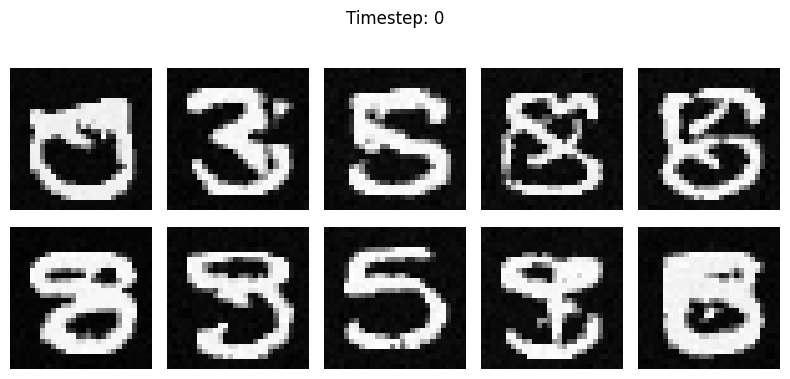

In [15]:
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

# ... (Previous code: model, encoder, theta, alpha, beta setup) ...

n_samples = 50
s = 100.0  # Set scale > 0 to see the guidance effect
img_size = 28
device = "cuda"

# Start with random noise
xt = torch.randn(n_samples, 1, img_size, img_size).to(device)

for i in reversed(range(timesteps)):
    t = torch.tensor([i] * n_samples, device=device)
    t_float = t.float() / timesteps
    
    # 1. Unconditional prediction (no grad needed)
    with torch.no_grad():
        eps_pred = model(xt, t_float)
    
    alpha_t = alpha[i]
    alpha_bar_t = alpha_bar[i]
    beta_t = beta[i]

    # Standard Diffusion Mean
    mean = (xt - ((1 - alpha_t) / torch.sqrt(1 - alpha_bar_t)) * eps_pred) / torch.sqrt(alpha_t)

    # 2. uLSIF Guidance (Requires Grad)
    # Use a clone that tracks gradients
    xt_for_grad = xt.detach().requires_grad_(True)
    
    features = encoder(xt_for_grad)
    ratio = features @ theta
    log_r = torch.log(torch.clamp(ratio, min=1e-8))
    
    # Calculate gradient of log-ratio w.r.t xt
    guide_score = torch.autograd.grad(log_r.sum(), xt_for_grad)[0]
    
    # Update mean with guidance
    mean = mean + s * beta_t * guide_score
    
    # 3. Step to next xt-1
    if i > 0:
        noise = torch.randn_like(xt)
        xt = mean + torch.sqrt(beta_t) * noise
    else:
        xt = mean

    # 4. Live Plotting
    if i % 20 == 0 or i == 0:
        clear_output(wait=True)
    
        imgs = xt[:10].detach().cpu()
    
        fig, axes = plt.subplots(2, 5, figsize=(8, 4))
        axes = axes.flatten()
    
        for j in range(10):
            axes[j].imshow(imgs[j, 0].numpy(), cmap='gray')
            axes[j].axis('off')
    
        plt.suptitle(f"Timestep: {i}")
        plt.tight_layout()
        plt.show()